In [6]:
#Data Manipulation specific
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
from scipy.stats import rankdata

#from scipy import signal
from netCDF4 import Dataset
#from osgeo import gdal
#Visualisation specific
#import seaborn as sns 
import matplotlib.pyplot as plt
#from mpl_toolkits.basemap import Basemap

import rasterio
from rasterio.transform import from_origin


In [2]:
!free -g

              total        used        free      shared  buff/cache   available
Mem:            376          67         131           1         177         304
Swap:             0           0           0


**Read NC data**

In [4]:
# Load dataset
ds = xr.open_dataset("/Users/workad/Workspace/Data-Other/Article3_data/vv.nc", engine="netcdf4")  # Load NetCDF file
ds = ds.sel(latitude=slice(40, 20))
ds = ds.sel(longitude=slice(-17, 1))
ds = ds[['w']] #keep only the variable z
ds

<xarray.Dataset> Size: 357MB
Dimensions:         (valid_time: 408, pressure_level: 37, latitude: 81,
                     longitude: 73)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 3kB 1991-01-01 ... 2024-12-01
    expver          (valid_time) <U4 7kB ...
  * pressure_level  (pressure_level) float64 296B 1e+03 975.0 950.0 ... 2.0 1.0
  * latitude        (latitude) float64 648B 40.0 39.75 39.5 ... 20.5 20.25 20.0
  * longitude       (longitude) float64 584B -17.0 -16.75 -16.5 ... 0.5 0.75 1.0
    number          int64 8B ...
Data variables:
    w               (valid_time, pressure_level, latitude, longitude) float32 357MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

In [ ]:
#Significance testing functions
def fdr_correction(p_values_2d, alpha=0.05):
    """Benjamini-Hochberg FDR correction for a 2D field of p-values.
    Returns boolean mask: True = significant after FDR correction."""
    flat = p_values_2d.flatten()
    n = len(flat)
    # Rank ascending (NaNs handled by masking)
    valid = ~np.isnan(flat)
    ranks = np.zeros(n)
    ranks[valid] = rankdata(flat[valid])
    # BH threshold: p <= (rank/n) * alpha
    threshold = (ranks / n) * alpha
    sig_flat = (flat <= threshold) & valid
    return sig_flat.reshape(p_values_2d.shape)


def percentile_significance(observed_da, climatology_da, time_dim, alpha=0.05, fdr=True):
    clim = climatology_da.values
    obs  = observed_da.values
    n    = clim.shape[0]
    p_values = np.sum(np.abs(clim) >= np.abs(obs[np.newaxis, :, :]), axis=0) / n
    if fdr:
        return fdr_correction(p_values, alpha=alpha)
    else:
        return p_values <= alpha


def ttest_significance(observed_da, climatology_da, time_dim, alpha=0.05, fdr=False):
    """
    Two-tailed Student's t-test for a single-year anomaly.
    t = anomaly / std(climatology), df = n-1.
    Land (NaN) cells are explicitly excluded.
    """
    clim = climatology_da.values
    obs  = observed_da.values
    n    = clim.shape[0]
    sigma = np.nanstd(clim, axis=0, ddof=1)
    with np.errstate(invalid='ignore', divide='ignore'):
        t_stat = obs / sigma
    p_values = 2 * stats.t.sf(np.abs(t_stat), df=n - 1)
    land_mask = np.isnan(obs) | (sigma == 0)
    p_values[land_mask] = np.nan
    if fdr:
        return fdr_correction(p_values, alpha=alpha)
    else:
        sig = p_values <= alpha
        sig[land_mask] = False
        return sig


def bootstrap_composite_significance(event_dates, climatology_da, time_dim,
                                     n_bootstrap=1000, alpha=0.05, fdr=False,
                                     random_seed=42):
    """
    Bootstrap significance test for a COMPOSITE of N events.

    Builds a null distribution by drawing N random time steps 1000 times and
    computing their composite mean. p-value = fraction of random composites at
    least as extreme as the observed composite.

    Land cells (NaN in observed composite) are explicitly excluded from the
    output mask to prevent NaN >= NaN comparisons from falsely marking land
    as significant.

    Args:
        event_dates   : list of coordinate values to select
        climatology_da: (time, lat, lon) DataArray of full climatological record
        time_dim      : name of the time dimension ('date' or 'year')
        n_bootstrap   : number of bootstrap samples (default 1000)
        alpha         : significance level (default 0.05)
        fdr           : apply BH-FDR correction (default False — over-conservative
                        for spatially correlated climate fields)
        random_seed   : reproducibility seed

    Returns:
        sig_mask      : (lat, lon) boolean array — True = significant ocean cells only
        obs_composite : (lat, lon) numpy array of observed composite mean
    """
    rng = np.random.default_rng(random_seed)
    n_events = len(event_dates)

    # Observed composite mean
    obs_composite = climatology_da.sel({time_dim: event_dates}).mean(dim=time_dim).values

    # Land mask derived from NaN in the observed composite
    land_mask = np.isnan(obs_composite)

    # Build null distribution
    clim_vals = climatology_da.values  # (n_time, lat, lon)
    n_clim    = clim_vals.shape[0]

    boot_composites = np.stack([
        np.nanmean(clim_vals[rng.integers(0, n_clim, size=n_events)], axis=0)
        for _ in range(n_bootstrap)
    ])  # (n_bootstrap, lat, lon)

    # Two-tailed empirical p-value
    p_values = np.sum(
        np.abs(boot_composites) >= np.abs(obs_composite[np.newaxis]), axis=0
    ) / n_bootstrap

    # Exclude land before thresholding so NaN cells cannot pass
    p_values[land_mask] = np.nan

    if fdr:
        sig_mask = fdr_correction(p_values, alpha=alpha)
    else:
        sig_mask = p_values <= alpha

    sig_mask[land_mask] = False  # belt-and-suspenders: zero out any residual land flags

    return sig_mask, obs_composite

**Seasonal VV anomalies and p_values**

In [8]:
import pandas as pd
import numpy as np
import xarray as xr
from scipy.stats import ttest_ind

# Convert time to datetime
ds = ds.assign_coords(date=pd.to_datetime(ds['valid_time'].data.astype(str), format='ISO8601'))

# Lists to collect results
anomaly_list = []

for p in ds['pressure_level'].values:
    dsh = ds.sel(pressure_level=p).squeeze()
    df = dsh['w'].to_dataframe().reset_index()
    
    df['year'] = df['valid_time'].dt.year
    df['month'] = df['valid_time'].dt.month
    df['season'] = np.select(
        [df['month'].isin([12, 1, 2]), df['month'].isin([3, 4, 5]),
         df['month'].isin([6, 7, 8]), df['month'].isin([9, 10, 11])],
        ['DJF', 'MAM', 'JJA', 'SON'],
        default='UNK'
    )
    df['season_year'] = df['year']
    df.loc[df['month'] == 12, 'season_year'] += 1

    seasonal = df.groupby(['latitude', 'longitude', 'season_year', 'season'])['w'].mean().reset_index()
    clim = seasonal.groupby(['latitude', 'longitude', 'season'])['w'].mean().reset_index()
    clim.rename(columns={'w': 'w_clim'}, inplace=True)

    merged = pd.merge(seasonal, clim, on=['latitude', 'longitude', 'season'], how='left')
    merged['w_anomaly'] = merged['w'] - merged['w_clim']
    merged['date'] = merged['season'].astype(str) + '_' + merged['season_year'].astype(str)

    # Save anomaly
    da = merged.set_index(['date', 'latitude', 'longitude'])[['w_anomaly']].to_xarray()['w_anomaly']
    da = da.expand_dims(pressure_level=[p])
    anomaly_list.append(da)

# Final xarray outputs
anomaly_all_levels = xr.concat(anomaly_list, dim='pressure_level').sortby('pressure_level')

anomaly_ds = xr.Dataset({'w_anomaly': anomaly_all_levels})


In [9]:
anomaly_ds

<xarray.Dataset> Size: 120MB
Dimensions:         (pressure_level: 37, date: 137, latitude: 81, longitude: 73)
Coordinates:
  * pressure_level  (pressure_level) float64 296B 1.0 2.0 3.0 ... 975.0 1e+03
  * date            (date) object 1kB 'DJF_1991' 'DJF_1992' ... 'SON_2024'
  * latitude        (latitude) float64 648B 20.0 20.25 20.5 ... 39.5 39.75 40.0
  * longitude       (longitude) float64 584B -17.0 -16.75 -16.5 ... 0.5 0.75 1.0
Data variables:
    w_anomaly       (pressure_level, date, latitude, longitude) float32 120MB ...

In [10]:
# Load dataset
dsu = xr.open_dataset('/Users/workad/Workspace/Data-Other/Article3_data/u.nc', engine="netcdf4")  # Load NetCDF file
dsu = dsu.sel(latitude=slice(40, 20))
dsu = dsu.sel(longitude=slice(-17, 1))
dsu = dsu[['u']] #keep only the variable u

dsv = xr.open_dataset('/Users/workad/Workspace/Data-Other/Article3_data/v.nc', engine="netcdf4")  # Load NetCDF file
dsv = dsv.sel(latitude=slice(40, 20))
dsv = dsv.sel(longitude=slice(-17, 1))
dsv = dsv[['v']] #keep only the variable v
dsu

<xarray.Dataset> Size: 357MB
Dimensions:         (valid_time: 408, pressure_level: 37, latitude: 81,
                     longitude: 73)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 3kB 1991-01-01 ... 2024-12-01
    expver          (valid_time) <U4 7kB ...
  * pressure_level  (pressure_level) float64 296B 1e+03 975.0 950.0 ... 2.0 1.0
  * latitude        (latitude) float64 648B 40.0 39.75 39.5 ... 20.5 20.25 20.0
  * longitude       (longitude) float64 584B -17.0 -16.75 -16.5 ... 0.5 0.75 1.0
    number          int64 8B ...
Data variables:
    u               (valid_time, pressure_level, latitude, longitude) float32 357MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

In [12]:
# Convert time to datetime
dsv = dsv.assign_coords(date=pd.to_datetime(dsv['valid_time'].data.astype(str), format='ISO8601'))

# Lists to collect results
vanomaly_list = []

for p in dsu['pressure_level'].values:
    dsvh = dsv.sel(pressure_level=p).squeeze()
    dfv = dsvh['v'].to_dataframe().reset_index()
    
    dfv['year'] = dfv['valid_time'].dt.year
    dfv['month'] = dfv['valid_time'].dt.month
    dfv['season'] = np.select(
        [dfv['month'].isin([12, 1, 2]), dfv['month'].isin([3, 4, 5]),
         dfv['month'].isin([6, 7, 8]), dfv['month'].isin([9, 10, 11])],
        ['DJF', 'MAM', 'JJA', 'SON'],
        default='UNK'
    )
    dfv['season_year'] = dfv['year']
    dfv.loc[dfv['month'] == 12, 'season_year'] += 1

    seasonal = dfv.groupby(['latitude', 'longitude', 'season_year', 'season'])['v'].mean().reset_index()
    clim = seasonal.groupby(['latitude', 'longitude', 'season'])['v'].mean().reset_index()
    clim.rename(columns={'v': 'v_clim'}, inplace=True)

    merged = pd.merge(seasonal, clim, on=['latitude', 'longitude', 'season'], how='left')
    merged['v_anomaly'] = merged['v'] - merged['v_clim']
    merged['date'] = merged['season'].astype(str) + '_' + merged['season_year'].astype(str)

    # Save anomaly
    da = merged.set_index(['date', 'latitude', 'longitude'])[['v_anomaly']].to_xarray()['v_anomaly']
    da = da.expand_dims(pressure_level=[p])
    vanomaly_list.append(da)

# Final xarray outputs
vanomaly_all_levels = xr.concat(vanomaly_list, dim='pressure_level').sortby('pressure_level')

vanomaly_ds = xr.Dataset({'v_anomaly': vanomaly_all_levels})

In [13]:
# Convert time to datetime
dsu = dsu.assign_coords(date=pd.to_datetime(dsu['valid_time'].data.astype(str), format='ISO8601'))

# Lists to collect results
uanomaly_list = []

for p in dsu['pressure_level'].values:
    dsuh = dsu.sel(pressure_level=p).squeeze()
    dfu = dsuh['u'].to_dataframe().reset_index()
    
    dfu['year'] = dfu['valid_time'].dt.year
    dfu['month'] = dfu['valid_time'].dt.month
    dfu['season'] = np.select(
        [dfu['month'].isin([12, 1, 2]), dfu['month'].isin([3, 4, 5]),
         dfu['month'].isin([6, 7, 8]), dfu['month'].isin([9, 10, 11])],
        ['DJF', 'MAM', 'JJA', 'SON'],
        default='UNK'
    )
    dfu['season_year'] = dfu['year']
    dfu.loc[dfu['month'] == 12, 'season_year'] += 1

    seasonal = dfu.groupby(['latitude', 'longitude', 'season_year', 'season'])['u'].mean().reset_index()
    clim = seasonal.groupby(['latitude', 'longitude', 'season'])['u'].mean().reset_index()
    clim.rename(columns={'u': 'u_clim'}, inplace=True)

    merged = pd.merge(seasonal, clim, on=['latitude', 'longitude', 'season'], how='left')
    merged['u_anomaly'] = merged['u'] - merged['u_clim']
    merged['date'] = merged['season'].astype(str) + '_' + merged['season_year'].astype(str)

    # Save anomaly
    da = merged.set_index(['date', 'latitude', 'longitude'])[['u_anomaly']].to_xarray()['u_anomaly']
    da = da.expand_dims(pressure_level=[p])
    uanomaly_list.append(da)

# Final xarray outputs
uanomaly_all_levels = xr.concat(uanomaly_list, dim='pressure_level').sortby('pressure_level')

uanomaly_ds = xr.Dataset({'u_anomaly': uanomaly_all_levels})

In [14]:
uanomaly_ds

<xarray.Dataset> Size: 120MB
Dimensions:         (pressure_level: 37, date: 137, latitude: 81, longitude: 73)
Coordinates:
  * pressure_level  (pressure_level) float64 296B 1.0 2.0 3.0 ... 975.0 1e+03
  * date            (date) object 1kB 'DJF_1991' 'DJF_1992' ... 'SON_2024'
  * latitude        (latitude) float64 648B 20.0 20.25 20.5 ... 39.5 39.75 40.0
  * longitude       (longitude) float64 584B -17.0 -16.75 -16.5 ... 0.5 0.75 1.0
Data variables:
    u_anomaly       (pressure_level, date, latitude, longitude) float32 120MB ...

**Plotting**

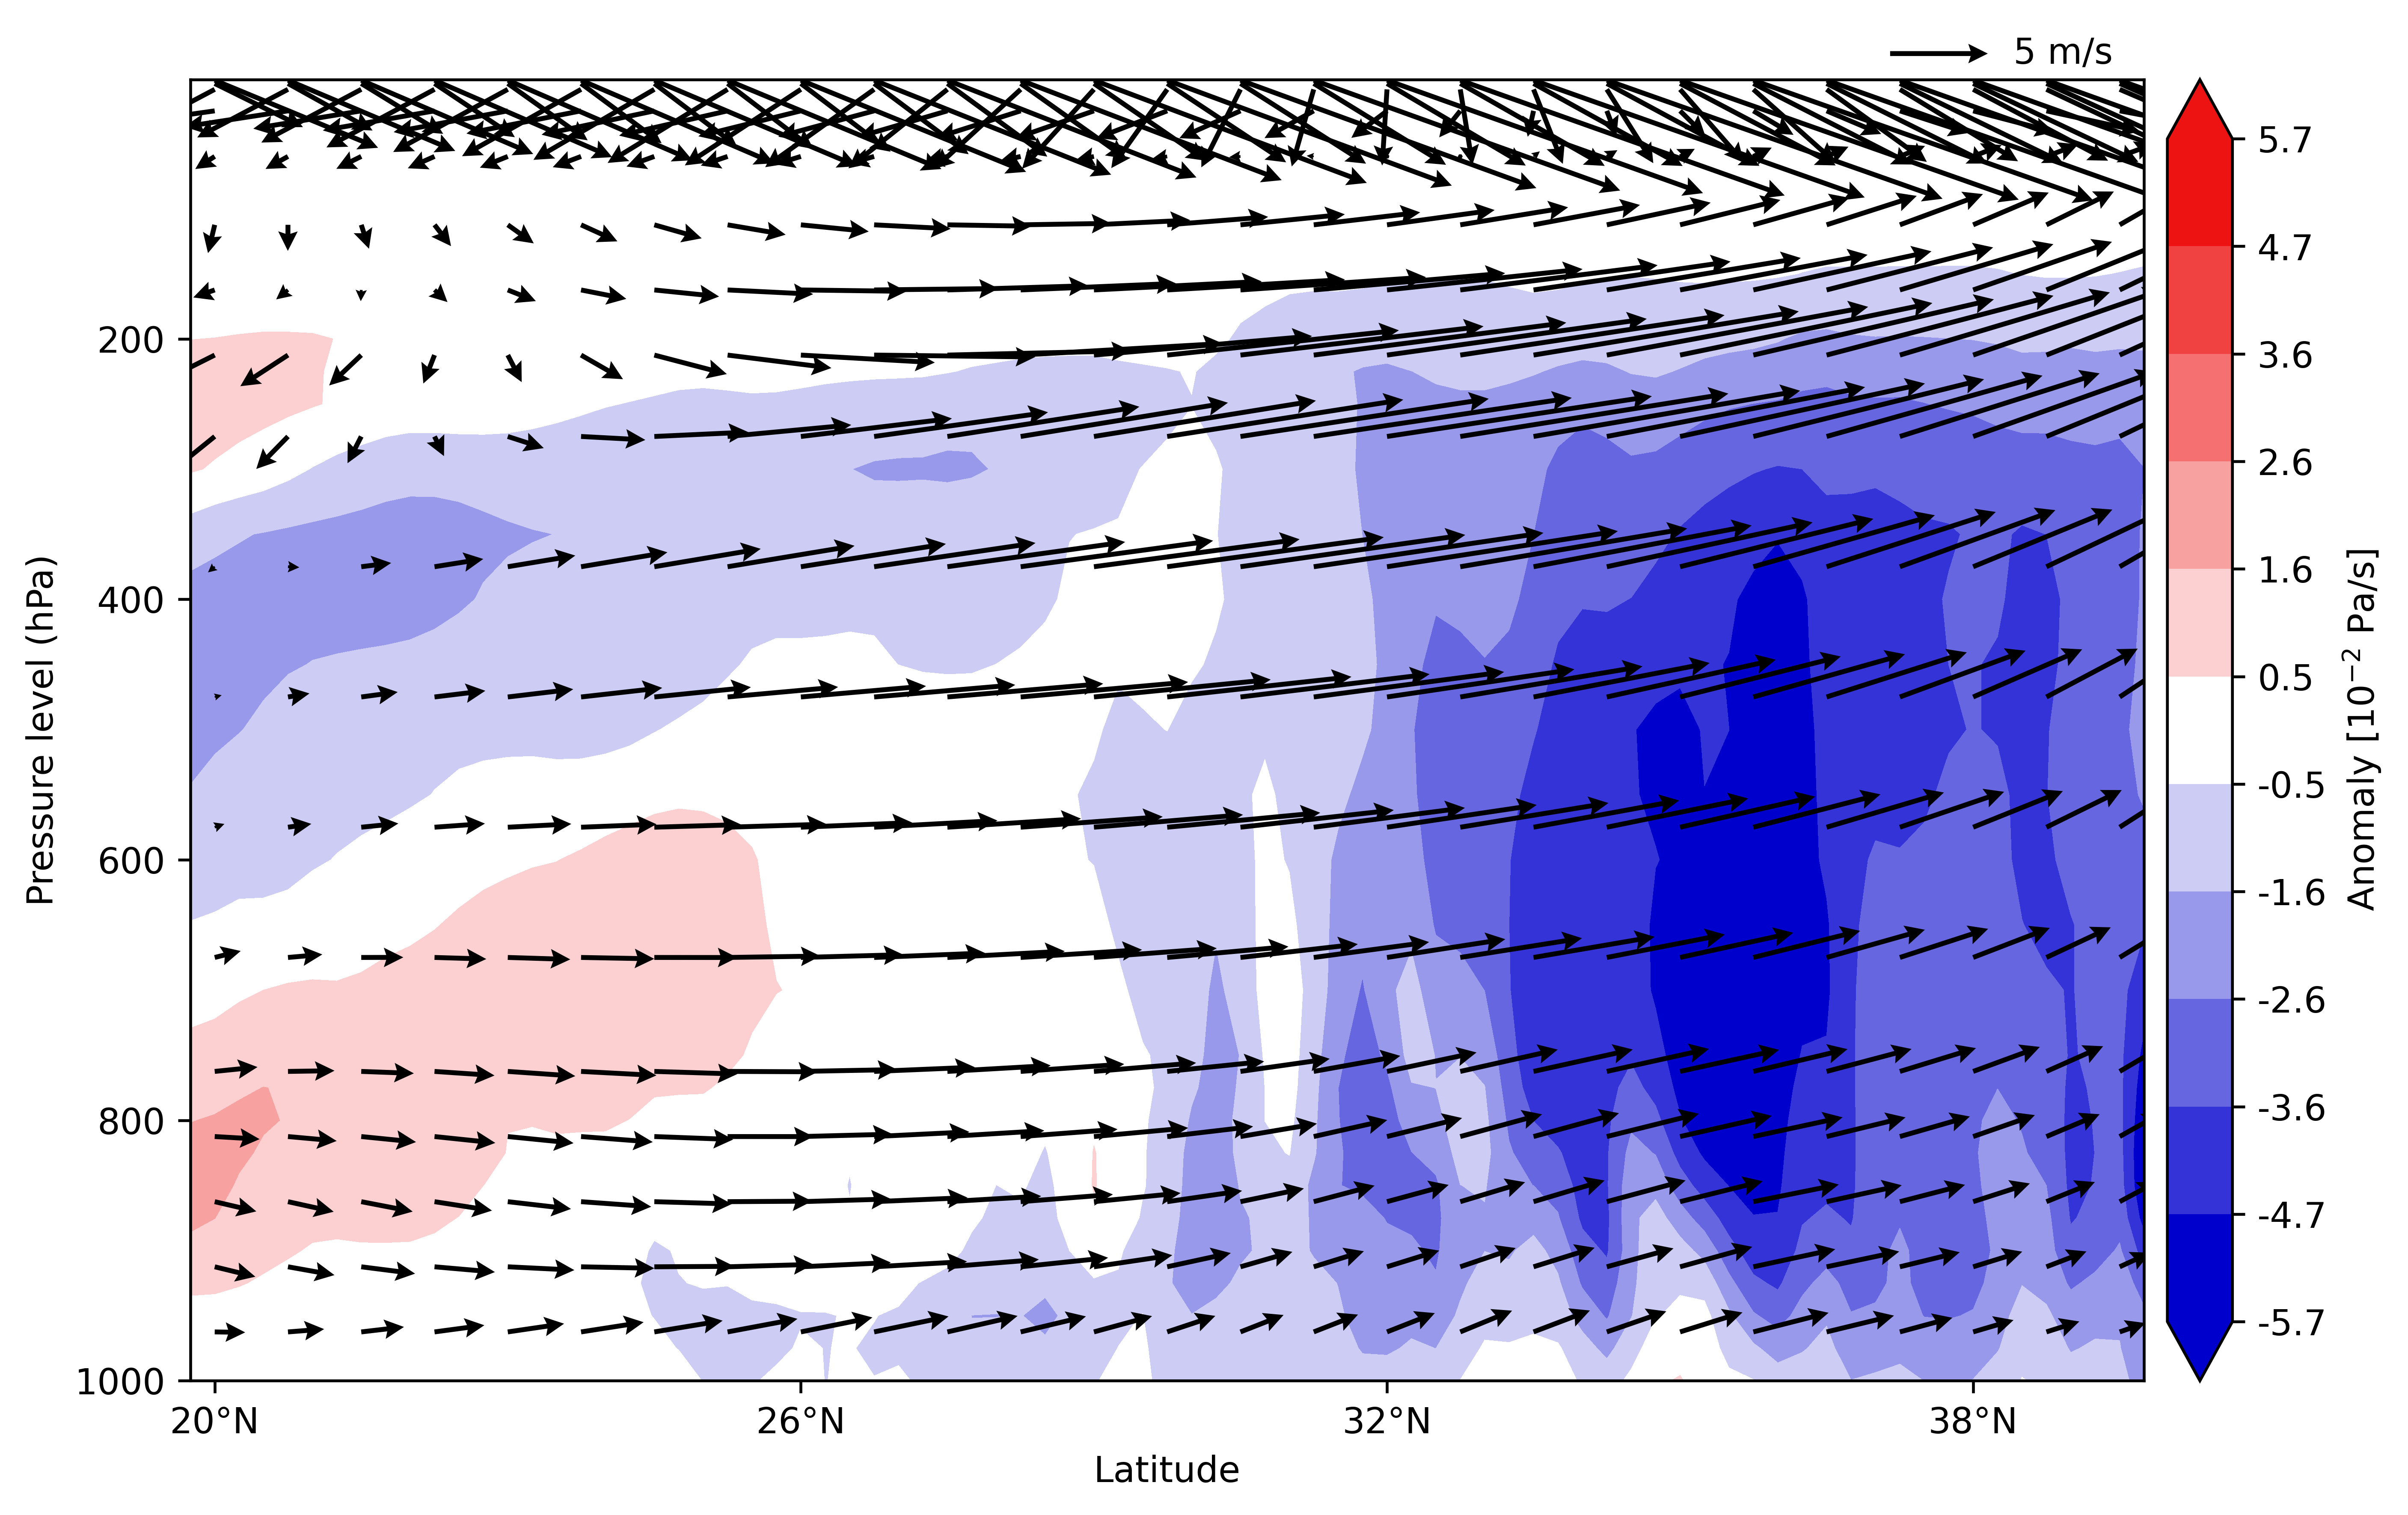

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np

# Mean meridional wind anomaly over longitude
wds_mean = anomaly_ds.mean(dim='longitude')
uds_mean = uanomaly_ds.mean(dim='longitude')
vds_mean = vanomaly_ds.mean(dim='longitude')

# Subset and average over time (date)
w_djf = anomaly_ds['w_anomaly'].sel(date='DJF_1996')
u_djf = uanomaly_ds['u_anomaly'].sel(date='DJF_1996')
v_djf = vanomaly_ds['v_anomaly'].sel(date='DJF_1996')

# Average over longitude
w_djf = w_djf.mean(dim='longitude') * 100
u_djf = u_djf.mean(dim='longitude').coarsen(latitude=3, pressure_level=2, boundary='trim').mean()
v_djf = v_djf.mean(dim='longitude').coarsen(latitude=3, pressure_level=2, boundary='trim').mean()

# Set contour levels (fewer colors)
abs_max = np.nanmax(np.abs(w_djf))
vmin = -abs_max
vmax = abs_max
levels = np.linspace(vmin, vmax,12)  # Reduce number of levels

# Custom colormap: Royal Blue -> White -> Red
colors = ['#0000CD', '#FFFFFF', '#ee1313']
custom_cmap = LinearSegmentedColormap.from_list("RoyalRed", colors, N=len(levels)-1)

#colors = ['#0000CD', '#FFFFFF', '#B22222']  # MediumBlue → White → FireBrick
#custom_cmap = LinearSegmentedColormap.from_list("StrongRedBlue", colors, N=len(levels)-1)
# Plotting
fig, ax = plt.subplots(figsize=(10, 6), dpi=600)

cf = ax.contourf(
    w_djf['latitude'],
    w_djf['pressure_level'],
    w_djf.transpose('pressure_level', 'latitude'),
    levels=levels,
    cmap=custom_cmap,
    extend='both'
)

# Define lat & pressure grid for quiver
lat = u_djf['latitude'].values
plev = u_djf['pressure_level'].values
# Create 2D meshgrid
LAT, PLEV = np.meshgrid(lat, plev)
# Overlay quiver
Q = ax.quiver(
    LAT, PLEV,
    u_djf.transpose('pressure_level', 'latitude'),# Zonal component 
    v_djf.transpose('pressure_level', 'latitude'), # Meridional component
    scale=100,  # Adjust as needed for arrow length
    width=0.0025,
    headwidth=4,
    headlength=4,
    headaxislength=3.5
)
ax.invert_yaxis()
ax.quiverkey(Q, 0.92, 1.02, 5, '5 m/s', labelpos='E', coordinates='axes')

# Use xarray to get the coordinates of significant points (no shape mismatch)
#sig_mask = significant_mask.where(significant_mask, drop=True)
#sig_mask = sig_mask.stack(points=('pressure_level', 'latitude'))
#lat_points = sig_mask['latitude'].values
#plev_points = sig_mask['pressure_level'].values

#Overlay significant grid points
#ax.scatter(lat_points, plev_points,color='green', s=5, marker='o',label='p < 0.05')

# Axis labels and title
ax.set_xlabel('Latitude')
ax.set_ylabel('Pressure level (hPa)')
ax.set_title(' ')
# Add colorbar with 1 decimal formatting
cbar = plt.colorbar(cf, ax=ax, orientation='vertical', pad=0.01, format='%.1f')
cbar.set_ticks(np.linspace(vmin, vmax, 12))
cbar.set_label(r'Anomaly [$10^{-2}$ Pa/s]') # Adjust units if needed

#Format x-ticks also
#w_djf = wds_mean['w_anomaly'].sel(date='SON_2020')
#latitudes = w_djf['latitude'].values
ax.set_xticks(lat[::8])  # e.g., every 20th latitude value for readability
ax.set_xticklabels([
    f'{abs(l):.0f}°{"N" if l > 0 else "S" if l < 0 else ""}' for l in lat[::8]
])

# Improve layout
plt.tight_layout()
plt.show()
fig.savefig("VV Anomaly DJF 1996.png", dpi=600, bbox_inches="tight", format="png")


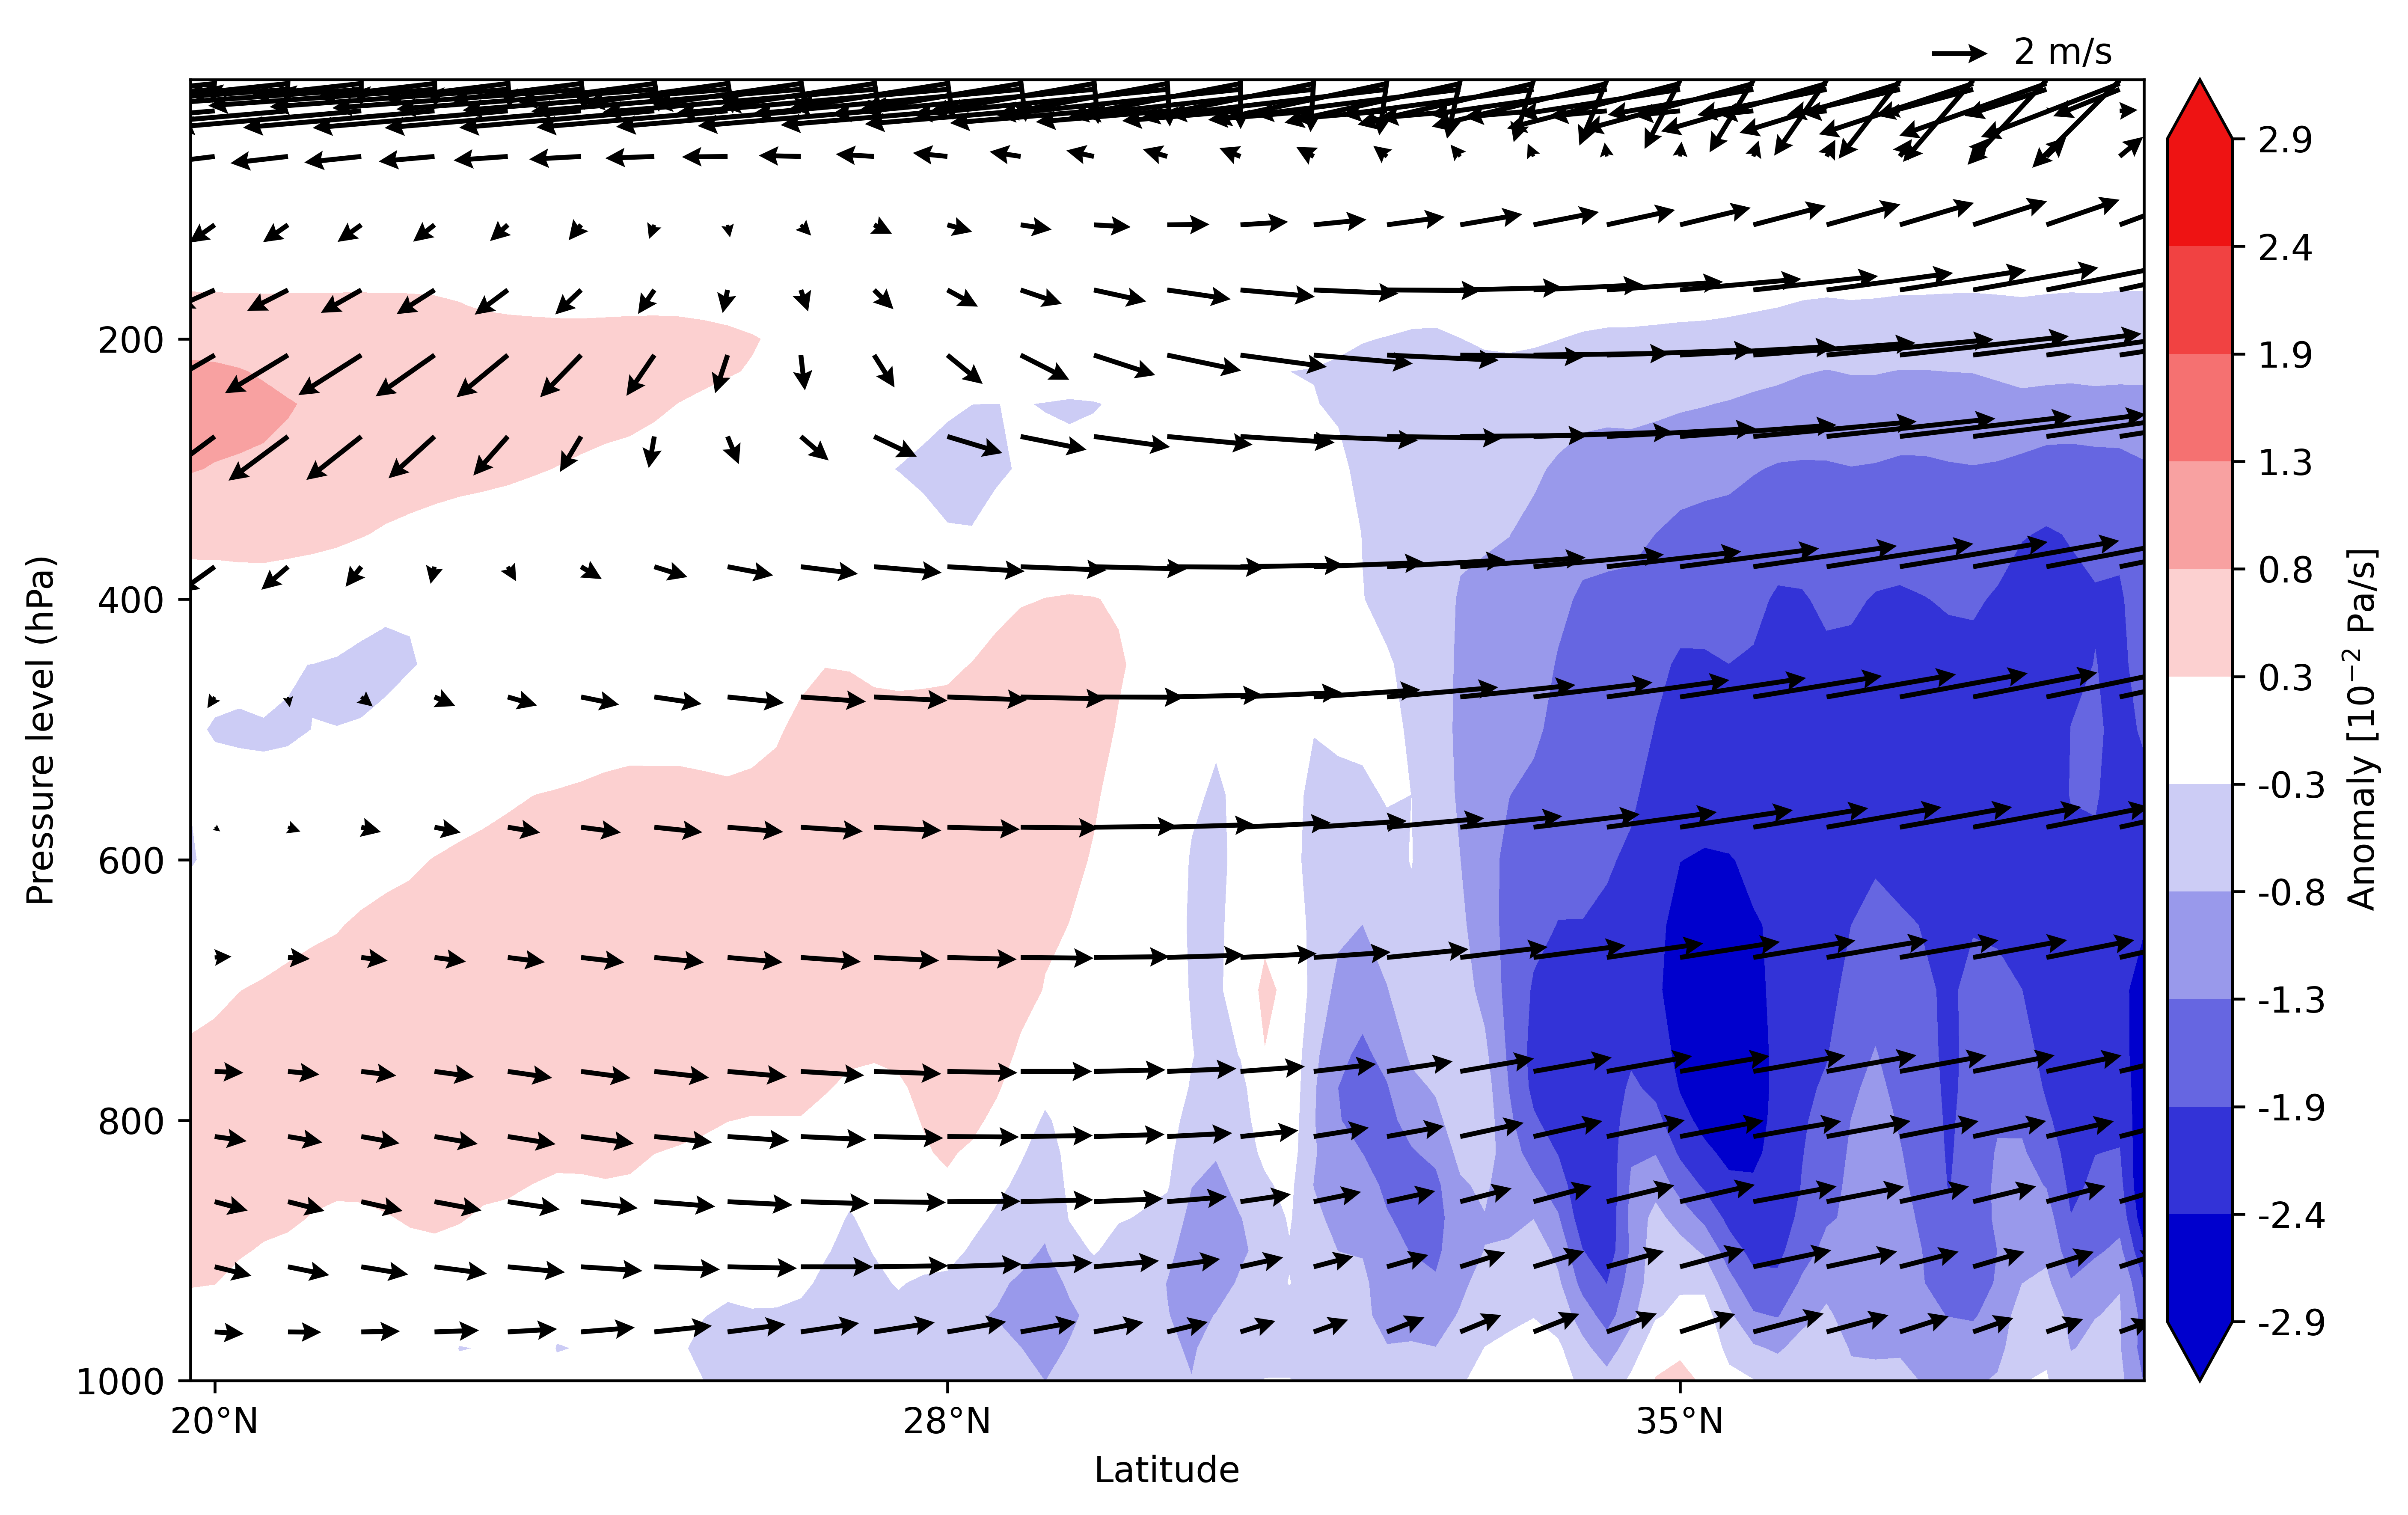

In [45]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np

# Mean meridional wind anomaly over longitude
#wds_mean = anomaly_ds.mean(dim='longitude')
#uds_mean = uanomaly_ds.mean(dim='longitude')
#vds_mean = vanomaly_ds.mean(dim='longitude')
#pval_mean = pval_ds.mean(dim='longitude')

# Extract dates that are DJF
#dry_years = [2000, 2001, 2020, 2022, 2023]
wet_years = [1996, 1997, 2010, 2014, 2018]
available_dates = set(map(str, anomaly_ds['date'].values))
djf_dates = [f"DJF_{year}" for year in wet_years if f"DJF_{year}" in available_dates]

# Subset and average over time (date)
w_djf = anomaly_ds['w_anomaly'].sel(date=djf_dates).mean(dim='date')
u_djf = uanomaly_ds['u_anomaly'].sel(date=djf_dates).mean(dim='date')
v_djf = vanomaly_ds['v_anomaly'].sel(date=djf_dates).mean(dim='date')
# Average over longitude
w_djf = w_djf.mean(dim='longitude') * 100
u_djf = u_djf.mean(dim='longitude').coarsen(latitude=3, pressure_level=2, boundary='trim').mean()
v_djf = v_djf.mean(dim='longitude').coarsen(latitude=3, pressure_level=2, boundary='trim').mean()

#w_djf2023 = wds_mean['w_anomaly'].sel(date='DJF_2021')
#u_djf2023 = uds_mean['u_anomaly'].sel(date='DJF_2021')
#v_djf2023 = vds_mean['v_anomaly'].sel(date='DJF_2021')
#pval_djf2023 = pval_mean.sel(date='DJF_2021')
#significant_mask = (pval_djf2023 < 0.05)

# Optional: round data values (for cleaner contours) and reduce arrow density:
#w_djf2023 = w_djf2023.round(2)
#w_djf2023 = w_djf2023.coarsen(latitude=1, pressure_level=1, boundary='trim').mean()
#u_djf2023 = u_djf2023.coarsen(latitude=3, pressure_level=2,boundary='trim').mean()
#v_djf2023 = v_djf2023.coarsen(latitude=3, pressure_level=2,boundary='trim').mean()
#pval_djf2023 = pval_djf2023.coarsen(latitude=3, pressure_level=2, boundary='trim').mean()

# Set contour levels (fewer colors)
abs_max = np.nanmax(np.abs(w_djf))
vmin = -abs_max
vmax = abs_max
levels = np.linspace(vmin, vmax,12)  # Reduce number of levels

# Custom colormap: Royal Blue -> White -> Red
colors = ['#0000CD', '#FFFFFF', '#ee1313']
custom_cmap = LinearSegmentedColormap.from_list("RoyalRed", colors, N=len(levels)-1)

#colors = ['#0000CD', '#FFFFFF', '#B22222']  # MediumBlue → White → FireBrick
#custom_cmap = LinearSegmentedColormap.from_list("StrongRedBlue", colors, N=len(levels)-1)
# Plotting
fig, ax = plt.subplots(figsize=(10, 6), dpi=600)

cf = ax.contourf(
    w_djf['latitude'],
    w_djf['pressure_level'],
    w_djf.transpose('pressure_level', 'latitude'),
    levels=levels,
    cmap=custom_cmap,
    extend='both'
)

# Define lat & pressure grid for quiver
lat = u_djf['latitude'].values
plev = u_djf['pressure_level'].values
# Create 2D meshgrid
LAT, PLEV = np.meshgrid(lat, plev)
# Overlay quiver
Q = ax.quiver(
    LAT, PLEV,
    u_djf.transpose('pressure_level', 'latitude'),# Zonal component 
    v_djf.transpose('pressure_level', 'latitude'), # Meridional component
    scale=70,  # Adjust as needed for arrow length
    width=0.0025,
    headwidth=4,
    headlength=4,
    headaxislength=3.5
)
ax.invert_yaxis()
ax.quiverkey(Q, 0.92, 1.02, 2, '2 m/s', labelpos='E', coordinates='axes')

# Use xarray to get the coordinates of significant points (no shape mismatch)
#sig_mask = significant_mask.where(significant_mask, drop=True)
#sig_mask = sig_mask.stack(points=('pressure_level', 'latitude'))
#lat_points = sig_mask['latitude'].values
#plev_points = sig_mask['pressure_level'].values

#Overlay significant grid points
#ax.scatter(lat_points, plev_points,color='green', s=5, marker='o',label='p < 0.05')

# Axis labels and title
ax.set_xlabel('Latitude')
ax.set_ylabel('Pressure level (hPa)')
ax.set_title(' ')
# Add colorbar with 1 decimal formatting
cbar = plt.colorbar(cf, ax=ax, orientation='vertical', pad=0.01, format='%.1f')
cbar.set_ticks(np.linspace(vmin, vmax, 12))
cbar.set_label(r'Anomaly [$10^{-2}$ Pa/s]') # Adjust units if needed

#Format x-ticks also
#w_djf = wds_mean['w_anomaly'].sel(date='SON_2020')
#latitudes = w_djf['latitude'].values
ax.set_xticks(lat[::10])  # e.g., every 20th latitude value for readability
ax.set_xticklabels([
    f'{abs(l):.0f}°{"N" if l > 0 else "S" if l < 0 else ""}' for l in lat[::10]
])

# Improve layout
plt.tight_layout()
plt.show()
fig.savefig("VVCompositeAnomaly_WetDJF.png", dpi=600, bbox_inches="tight", format="png")

